In [ ]:
!pip install. "thefittest[torch]==0.3.0"

In [2]:
!pip install matplotlib networkx



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


## Iris flower data set

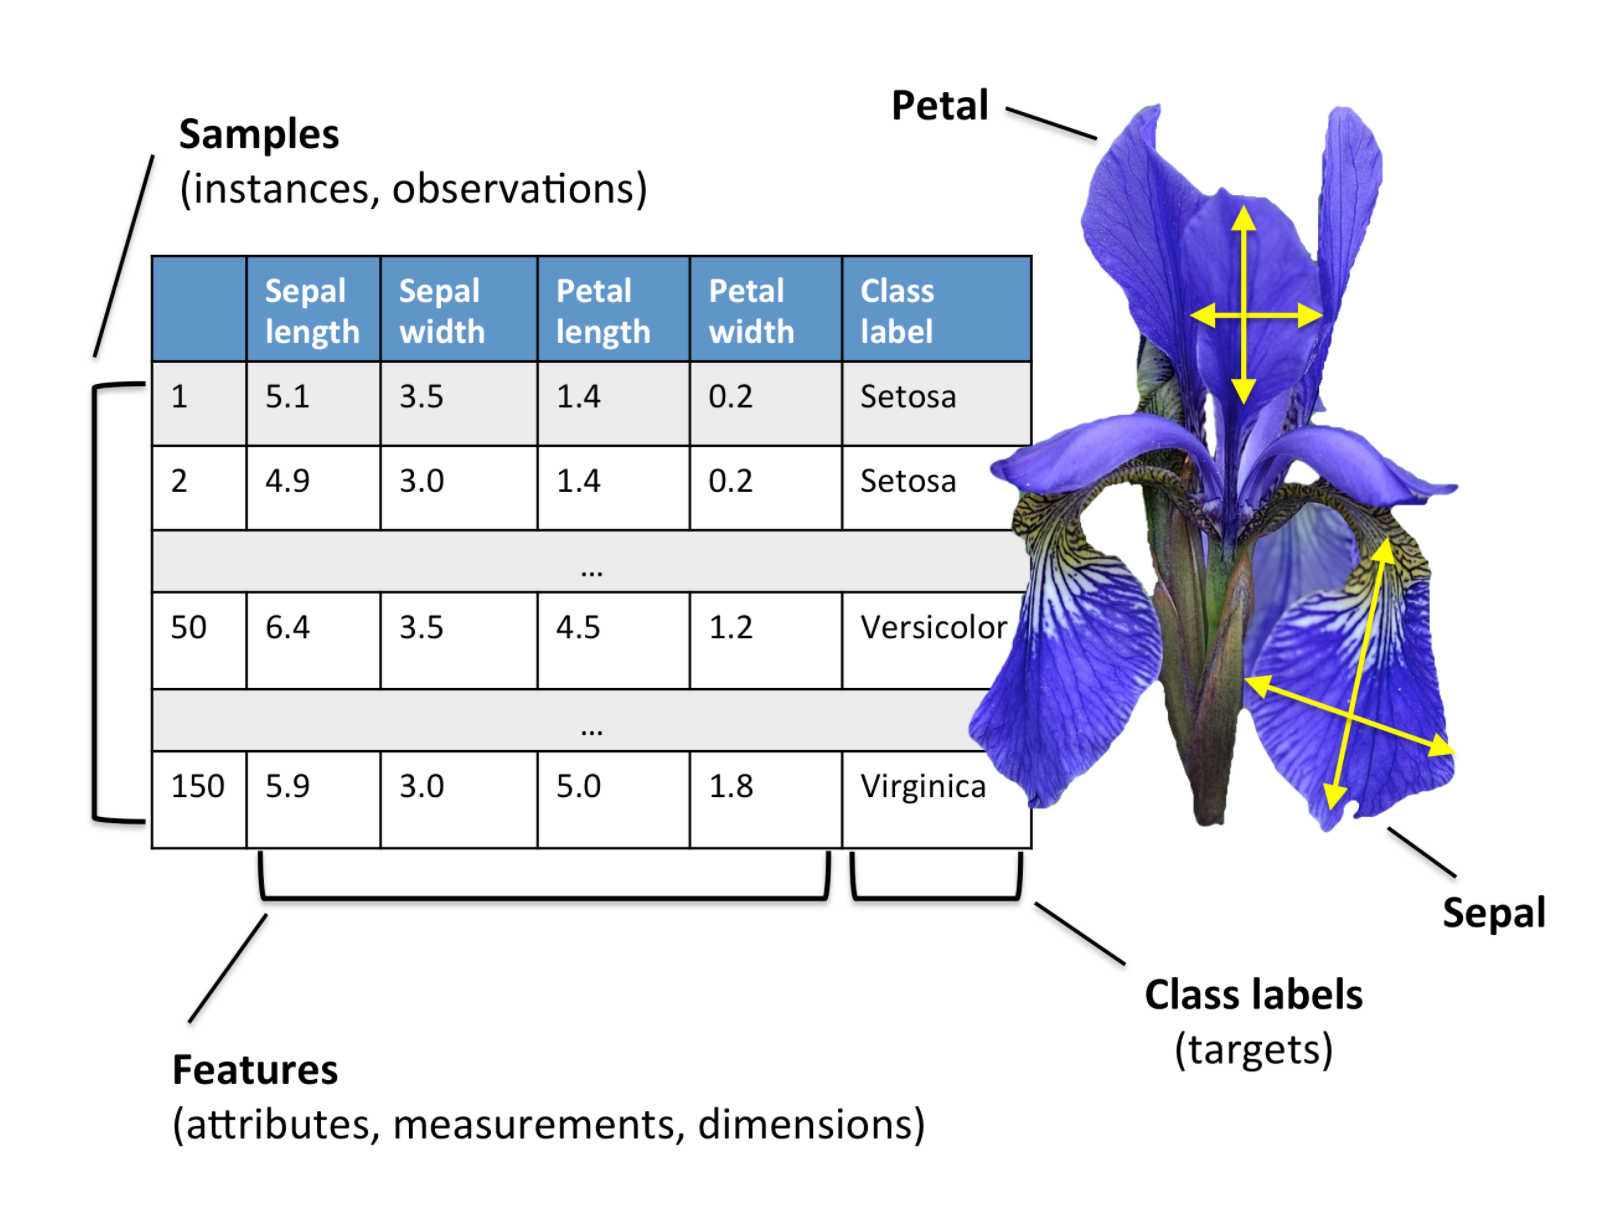

In [8]:
from thefittest.optimizers import SelfCGP
from thefittest.optimizers import SHAGA
from thefittest.benchmarks import IrisDataset
from thefittest.classifiers import GeneticProgrammingNeuralNetClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import minmax_scale
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score


data = IrisDataset()
X = data.get_X()
y = data.get_y()

X_scaled = minmax_scale(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.1)

model = GeneticProgrammingNeuralNetClassifier(n_iter=10,
                                              pop_size=10,
                                              optimizer=SelfCGP,
                                              optimizer_args={"show_progress_each": 1},
                                              weights_optimizer=SHAGA,
                                              weights_optimizer_args={"iters": 150, "pop_size": 150},
                                              use_fitness_cache=True)

model.fit(X_train, y_train)
predict = model.predict(X_test)


print("confusion_matrix: \n", confusion_matrix(y_test, predict))
print("f1_score: \n", f1_score(y_test, predict, average="macro"))

0-th iteration with the best fitness = 0.09490496226679779
1-th iteration with the best fitness = 0.07721860726424913
2-th iteration with the best fitness = 0.07721860726424913
3-th iteration with the best fitness = 0.07721860726424913
4-th iteration with the best fitness = 0.07721860726424913
5-th iteration with the best fitness = 0.07721860726424913
6-th iteration with the best fitness = 0.07721860726424913
7-th iteration with the best fitness = 0.07664221894731404
8-th iteration with the best fitness = 0.07664221894731404
confusion_matrix: 
 [[5 0 0]
 [0 3 0]
 [0 0 7]]
f1_score: 
 1.0


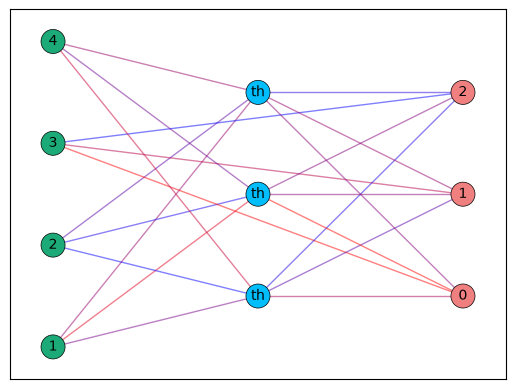

In [9]:
net = model.get_net()
net.plot()

## Regression problem

$$y = \frac{1}{2} x \sin(3 x)$$

In [10]:
import numpy as np


def problem(x):
    return np.sin(x[:,0]*3)*x[:,0]*0.5

In [15]:
from thefittest.regressors import GeneticProgrammingNeuralNetRegressor
from thefittest.optimizers import PDPGP

from sklearn.preprocessing import scale
from sklearn.metrics import r2_score


n_dimension = 1
left_border = -4.5
right_border = 4.5
sample_size = 100


X = np.array([np.linspace(left_border, right_border, sample_size)
              for _ in range(n_dimension)]).T
noise = np.random.normal(0, 0.1, size=sample_size)
y = problem(X) + noise

X_scaled = scale(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.1)

model = GeneticProgrammingNeuralNetRegressor(n_iter=10,
                                             pop_size=10,
                                             optimizer=PDPGP,
                                             optimizer_args={"show_progress_each": 1},
                                             weights_optimizer=SHAGA,
                                             weights_optimizer_args={"iters": 150, "pop_size": 150},
                                             use_fitness_cache=True)

model.fit(X_train, y_train)
predict = model.predict(X_test)

print("r2_score:", r2_score(y_test, predict))

0-th iteration with the best fitness = 0.9207943556577963
1-th iteration with the best fitness = 0.33472739976443555
2-th iteration with the best fitness = 0.33472739976443555
3-th iteration with the best fitness = 0.33472739976443555
4-th iteration with the best fitness = 0.33472739976443555
5-th iteration with the best fitness = 0.33472739976443555
6-th iteration with the best fitness = 0.33472739976443555
7-th iteration with the best fitness = 0.33472739976443555
8-th iteration with the best fitness = 0.33472739976443555
r2_score: 0.857695091792018


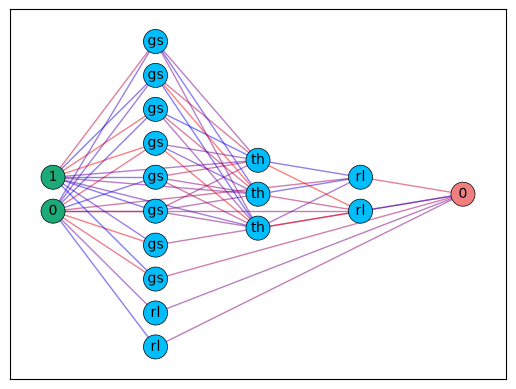

In [16]:
net = model.get_net()
net.plot()

In [17]:
from thefittest.optimizers import SelfCGP
from thefittest.benchmarks import IrisDataset
from thefittest.classifiers import GeneticProgrammingNeuralNetClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import minmax_scale
from sklearn.metrics import confusion_matrix, f1_score

import torch
import torch.optim as optim


# Загружаем данные
data = IrisDataset()
X = data.get_X()
y = data.get_y()

X_scaled = minmax_scale(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.1
)

# Определяем устройство
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Модель с Adam в качестве оптимизатора весов
model = GeneticProgrammingNeuralNetClassifier(
    n_iter=10,
    pop_size=10,
    optimizer=SelfCGP,
    optimizer_args={"show_progress_each": 1},
    weights_optimizer=optim.Adam,  # заменили SHAGA на Adam
    weights_optimizer_args={'iters': 1000, "lr": 0.01}, # `pop_size` игнорируется для torch.optim.* оптимизаторов.
    device=device  # добавили устройство
)

model.fit(X_train, y_train)
predict = model.predict(X_test)

print("confusion_matrix: \n", confusion_matrix(y_test, predict))
print("f1_score: \n", f1_score(y_test, predict, average="macro"))


Using device: cpu


/Users/user/thefittest/src/thefittest/base/_mlp.py:141: RuntimeWarning: `pop_size` игнорируется для torch.optim.* оптимизаторов.
  warnings.warn(
/Users/user/thefittest/src/thefittest/base/_mlp.py:141: RuntimeWarning: `pop_size` игнорируется для torch.optim.* оптимизаторов.
  warnings.warn(


0-th iteration with the best fitness = 0.1902856106098684
1-th iteration with the best fitness = 0.1623006928906546
2-th iteration with the best fitness = 0.07531244970198622
3-th iteration with the best fitness = 0.06739610198567503
4-th iteration with the best fitness = 0.05632926168987814
5-th iteration with the best fitness = 0.05632926168987814
6-th iteration with the best fitness = 0.054232003145426436
7-th iteration with the best fitness = 0.054232003145426436
8-th iteration with the best fitness = 0.054232003145426436
confusion_matrix: 
 [[2 0 0]
 [0 7 1]
 [0 0 5]]
f1_score: 
 0.9474747474747475


## Multiobjective Neural Network Optimization

In [18]:
from thefittest.optimizers import NSGPII

pareto_model = GeneticProgrammingNeuralNetClassifier(
    n_iter=10,
    pop_size=10,
    optimizer=NSGPII,  # Optimize prediction loss and network complexity.
    complexity="n_connections",  # Number of connections is the second objective.
    model_selection="best_error",
    optimizer_args={"show_progress_each": 1},
    weights_optimizer=optim.Adam,
    weights_optimizer_args={"iters": 1000, "lr": 0.01},
    device=device,
)

pareto_model.fit(X_train, y_train)
front = pareto_model.get_pareto_front()

/Users/user/thefittest/src/thefittest/base/_mlp.py:141: RuntimeWarning: `pop_size` игнорируется для torch.optim.* оптимизаторов.
  warnings.warn(


0-th iteration with Pareto front size = 4; best objectives = [f1=0.113562, f2=9]


/Users/user/thefittest/src/thefittest/base/_mlp.py:141: RuntimeWarning: `pop_size` игнорируется для torch.optim.* оптимизаторов.
  warnings.warn(


1-th iteration with Pareto front size = 6; best objectives = [f1=0.113562, f2=3]
2-th iteration with Pareto front size = 7; best objectives = [f1=0.113562, f2=3]
3-th iteration with Pareto front size = 6; best objectives = [f1=0.113562, f2=3]
4-th iteration with Pareto front size = 6; best objectives = [f1=0.113562, f2=3]
5-th iteration with Pareto front size = 7; best objectives = [f1=0.0508591, f2=3]
6-th iteration with Pareto front size = 8; best objectives = [f1=0.0508591, f2=3]
7-th iteration with Pareto front size = 10; best objectives = [f1=0.048817, f2=3]
8-th iteration with Pareto front size = 10; best objectives = [f1=0.048817, f2=3]


## Pareto Front and Selected Network Architectures

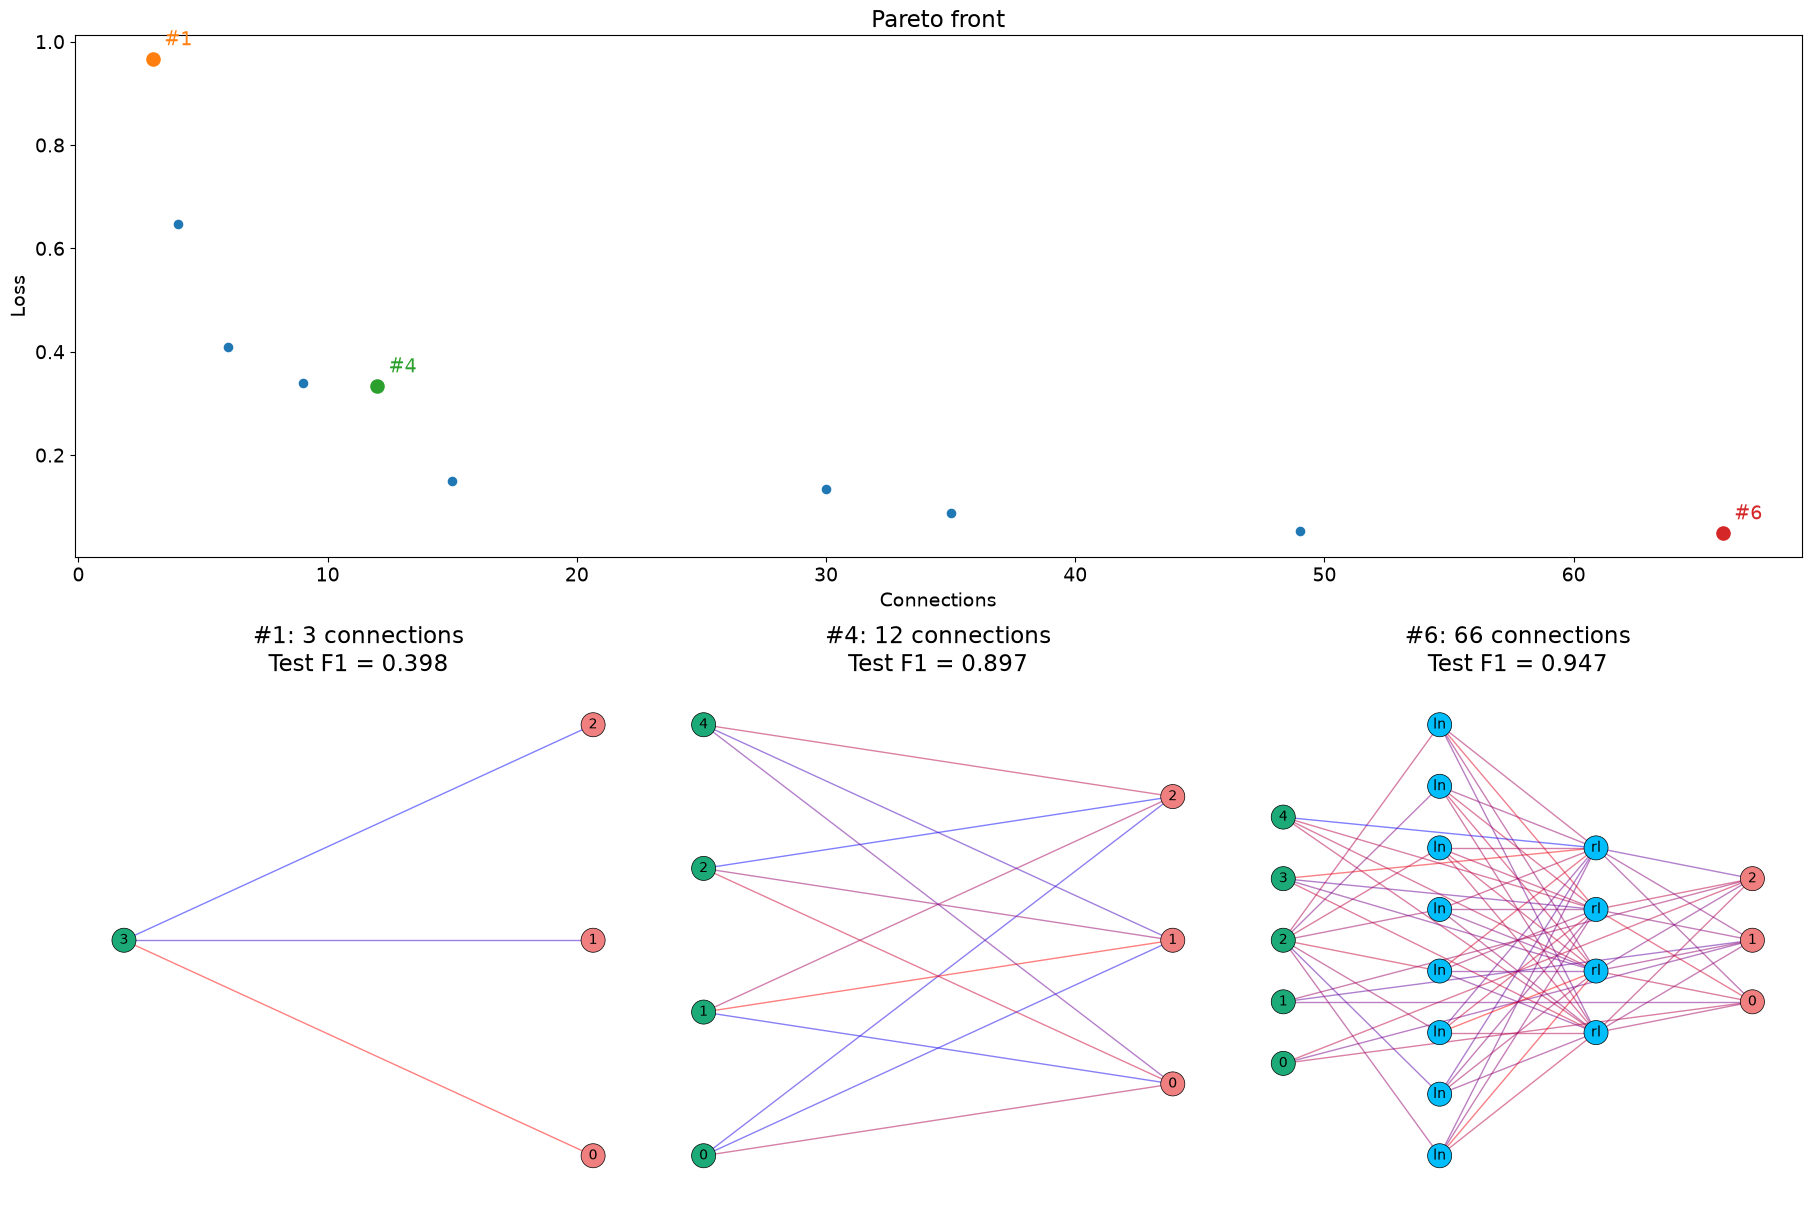

In [19]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 14})

losses, sizes = front["fitness"].T
_, unique = np.unique(front["fitness"], axis=0, return_index=True)
order = unique[np.argsort(sizes[unique])]
selected = order[np.linspace(0, len(order) - 1, min(3, len(order)), dtype=int)]

fig = plt.figure(figsize=(18, 12), layout="constrained")
grid = fig.add_gridspec(2, len(selected))
ax = fig.add_subplot(grid[0, :])
ax.scatter(sizes, losses, s=35)
ax.set(xlabel="Connections", ylabel="Loss", title="Pareto front")

active = pareto_model.selected_net_index_
for column, index in enumerate(selected):
    color = f"C{column + 1}"
    ax.scatter(sizes[index], losses[index], color=color, s=90)
    ax.annotate(
        f"#{index}", (sizes[index], losses[index]),
        xytext=(8, 10), textcoords="offset points", color=color,
    )

    pareto_model.select_net(int(index))
    predict = pareto_model.predict(X_test)
    score = f1_score(y_test, predict, average="macro")

    net_ax = fig.add_subplot(grid[1, column])
    pareto_model.get_net().plot(ax=net_ax)
    net_ax.set_title(
        f"#{index}: {int(sizes[index])} connections\nTest F1 = {score:.3f}"
    )
    net_ax.axis("off")

pareto_model.select_net(active)
plt.show()